In [4]:
import numpy as np
import scipy
import scipy.linalg
import random
import math
import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import qr, svd
from tqdm import tqdm

In [165]:
from numpy import ndarray

class myarray(ndarray):    
    @property
    def H(self):
        return self.conj().T

In [2]:
L = 6# Length of the chain
N = L // 2  # Number of particles
dt = 0.5  # Time step


In [3]:
def gram_schmidt(A):
    L, N = A.shape
    Q = np.zeros((L, N), dtype=np.complex_) 
    for j in range(N):
        v = A[:, j]
        for i in range(j):
            proj = np.vdot(Q[:, i].T, v) * Q[:, i]
            v = v - proj
        norm = np.linalg.norm(v)
        if norm > 1e-10: 
            Q[:, j] = v / norm
    return Q

In [94]:
def initialize_neel_state(L):
    N = int(L / 2)    
    U = np.zeros((L, N),dtype=np.complex_)    
    for i in range(N):
        U[2*i+1,i]=1+1j*0
    return U

def normalize(U):
    V=np.empty((L,N),dtype=np.complex_)
    for j in range(N):
        V[:,j]=U[:,j]
        for k in range(j):
            V[:,j]=V[:,j]-np.vdot(U[:,j],V[:,k])*V[:,k]
        V[:,j]=V[:,j]/np.linalg.norm(V[:,j])
    return V 

In [95]:
initialize_neel_state(5)

array([[0.+0.j, 0.+0.j],
       [1.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j],
       [0.+0.j, 1.+0.j],
       [0.+0.j, 0.+0.j]])

In [155]:

def evolve_state(U, h, gamma, dt):
    Ut=np.conjugate(np.transpose(U))
    D = np.transpose(np.dot(U, Ut))
    n_expectation = np.diag(D)
    # n=np.zeros(L,dtype=np.complex_)
    # for j in range(L):
    #     n[j]=D[j,j]
    

    # noise = np.random.normal(0, np.sqrt(gamma*dt), L)
    M=np.zeros((L,L),dtype=np.complex_)
    for i in range(L):
        M[i,i]=random.gauss(mu=0, sigma=np.sqrt(gamma*dt))/dt+gamma*(2*n_expectation[i]-1)/2
    # exp_factors = np.diag(np.exp(noise + gamma * (2 * n_expectation - 1) * dt))

    h2= h+1j*M
    # h1=h+1j*exp_factors
    # # print(h1)
    # print(h2)
    U=np.dot(scipy.linalg.expm(-1j*dt*h2),U)
    U= normalize(U)

    # Ut=np.conjugate(np.transpose(U))
    # D=np.transpose(np.dot(U,Ut))       
    # n=np.zeros(L,dtype=np.complex_)
    # for j in range(L):
    #     n[j]=D[j,j]
    # M=np.zeros((L,L),dtype=np.complex_)
    # for i in range(L):
    #     M[i,i]=random.gauss(mu=0, sigma=np.sqrt(gamma[g]*dt))/dt+gamma[g]*(2*n[i]-1)/2
    # h1=h+1j*M 
    # U=np.dot(scipy.linalg.expm(-1j*dt*h1),U)
    # U=normalize(U)



    return U



In [158]:
L=4
N=int(L/2)
U1= initialize_neel_state(4)
h = np.diag(np.ones(3), -1) + np.diag(np.ones(3), 1)



In [159]:
for t in range(10):
    U1= evolve_state(U1,h,0.1,0.5)

In [161]:
for t in range(20):
    U2 = evolve_state(U1,h,0.1,0.5)

In [163]:
U1

array([[ 0.        -0.33543126j,  0.        -0.49051112j],
       [-0.27966843+0.j        ,  0.10775524+0.j        ],
       [ 0.        -0.62041786j,  0.        -0.51373977j],
       [ 0.65142392+0.j        , -0.69559981+0.j        ]])

In [162]:
U2

array([[ 0.        -0.10026552j,  0.        -0.50184013j],
       [-0.71823431+0.j        , -0.19158762+0.j        ],
       [ 0.        -0.65030102j,  0.        -0.00449387j],
       [ 0.22626286+0.j        , -0.84346338+0.j        ]])

In [173]:
sum = 0

for i in range(4):
    for i1 in range(4):
        for k in range(2):
            for k1 in range(2):
                sum = sum + (U2).conj()[i1,k1]*U2[i1,k]*U1.conj()[i,k]*U1[i,k1]


In [174]:
sum

(1.9999999999999998+0j)

In [7]:

h = np.diag(np.ones(L-1), -1) + np.diag(np.ones(L-1), 1)


In [9]:
for time in range(20):
    U = evolve_state(U,h,0.1,dt)
    


# l=100
# D=np.transpose(np.dot(U,np.conjugate(np.transpose(U))))
# D_red=np.zeros((l,l),dtype=np.complex_)

# for i in range(l):
#     for j in range(l):
#         D_red[i,j]=D[i,j]
# ev=np.round(np.linalg.eig(D_red)[0].real,3)
# print(ev)

In [40]:
D=np.transpose(np.dot(U,np.conjugate(np.transpose(U))))
l=3
D_red=np.zeros((l,l),dtype=np.complex_)
for i in range(l):
    for j in range(l):
        D_red[i,j]=D[i,j]
ev=np.round(np.linalg.eig(D_red)[0].real,3)

In [52]:
ev

array([], dtype=float64)

In [123]:
A= 100
l=int(L/2)
S= np.zeros((1,l))

for i in range(l):
    print(f'{S_tot} is the value')
    
    S_tot=0
    print('one is done')
    for a in range(A):
    
        
        U = initialize_neel_state(L)

        for time in range(20):
            U = evolve_state(U,h,0.5,dt)


        D=np.transpose(np.dot(U,np.conjugate(np.transpose(U))))
        D_red=np.zeros((i+1,i+1),dtype=np.complex_)
        
        for k in range(i+1):
            for j in range(i+1):
                D_red[k,j]=D[k,j]

        
        ev=np.round(np.linalg.eig(D_red)[0].real,3)
        
        print(ev)
        
        S1=0
        for p in range(i):
            if(ev[p]>=1):
                ev[p]=1.-0.001
            if(ev[p]<=0):
                ev[p]=0.001
            S1=S1-ev[p]*math.log2(ev[p])-(1-ev[p])*math.log2(1-ev[p])
            
        
        S_tot=S_tot+S1
    print(S_tot)    
    S[0,i]= S_tot/A





43.82409820841228 is the value
one is done
[0.883]
[0.148]
[0.56]
[0.389]
[0.624]
[0.261]
[0.734]
[0.158]
[0.964]
[0.756]
[0.473]
[0.824]
[0.008]
[0.927]
[0.426]
[0.563]
[0.415]
[0.557]
[0.49]
[0.473]
[0.892]
[0.562]
[0.613]
[0.916]
[0.601]
[0.951]
[0.789]
[0.113]
[0.904]
[0.737]
[0.199]
[0.817]
[0.09]
[0.448]
[0.79]
[0.146]
[0.575]
[0.36]
[0.411]
[0.105]
[0.19]
[0.578]
[0.15]
[0.882]
[0.27]
[0.63]
[0.637]
[0.224]
[0.689]
[0.409]
[0.206]
[0.465]
[0.483]
[0.948]
[0.628]
[0.683]
[0.412]
[0.995]
[0.276]
[0.786]
[0.757]
[0.959]
[0.828]
[0.521]
[0.76]
[0.644]
[0.741]
[0.826]
[0.255]
[0.947]
[0.848]
[0.435]
[0.868]
[0.883]
[0.982]
[0.119]
[0.428]
[0.894]
[0.927]
[0.92]
[0.902]
[0.815]
[0.01]
[0.996]
[0.089]
[0.437]
[0.393]
[0.258]
[0.732]
[0.648]
[0.995]
[0.489]
[0.175]
[0.863]
[0.668]
[0.22]
[0.393]
[0.896]
[0.932]
[0.428]
0
0 is the value
one is done
[0.964 0.196]
[0.904 0.14 ]
[0.017 0.911]
[0.997 0.411]
[0.994 0.719]
[0.1   0.972]
[0.863 0.604]
[0.774 0.26 ]
[0.903 0.419]
[0.009 0.534]
[

In [125]:
S

array([[0.        , 0.47117429, 0.7960783 ]])

In [126]:
l=3
f=np.zeros(l)
for l in range(l):
    f[l]=math.sin(math.pi*l/L)
    

In [127]:
f

array([0.       , 0.5      , 0.8660254])

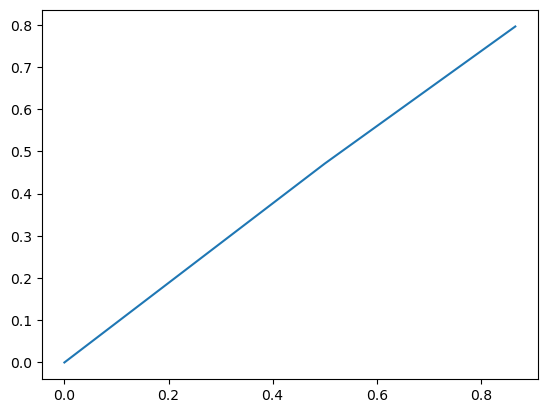

In [128]:
plt.plot(f,S[0,:])

In [73]:
L=100
length=int(L/2)
N=int(L/2)

dt=0.5
time=np.arange(0,10,dt)
w=11
gamma=np.linspace(0,1,w)
A=100
S_avg=np.zeros((w,length))
f=np.zeros(length)
l=50



In [208]:
len(time)

20

In [196]:

S_tot=0
D_tot=np.zeros((L,L),dtype=np.complex_)
gamma=np.linspace(0,1,w)

h=np.zeros((L,L))
p=1
for i in range(L):
    for j in range(L):
        if (i==j-1 or i==j+1):
            h[i,j]=p
print(h)


U=np.zeros((L,N),dtype=np.complex_)
for k in range(N):
    U[2*k+1,k]=1+1j*0
    
for t in time:
    # Ut=np.conjugate(np.transpose(U))
    # D=np.transpose(np.dot(U,Ut))       
    # n=np.zeros(L,dtype=np.complex_)
    # for j in range(L):
    #     n[j]=D[j,j]
    #     # print(n[j])
    # M=np.zeros((L,L),dtype=np.complex_)
    # for i in range(L):
    #     M[i,i]=random.gauss(mu=0, sigma=np.sqrt(gamma[1]*dt))/dt+gamma[1]*(2*n[i]-1)/2
    # h1=h+1j*M 
    # U=np.dot(scipy.linalg.expm(-1j*dt*h1),U)
    # U=normalize(U) 
    U= evolve_state(U,h,gamma[1],dt)
D=np.transpose(np.dot(U,np.conjugate(np.transpose(U))))


D_red=np.zeros((l,l),dtype=np.complex_)
for i in range(l):
    for j in range(l):
        D_red[i,j]=D[i,j]

        
ev=np.round(np.linalg.eig(D_red)[0].real,3)



S1=0
for i in range(l):
    if(ev[i]>=1):
        ev[i]=1-0.001
    if(ev[i]<=0):
        ev[i]=0.001
    S1=S1-ev[i]*math.log2(ev[i])-(1-ev[i])*math.log2(1-ev[i])
S_tot=S_tot+S1
print(S_tot)



[[0. 1. 0. ... 0. 0. 0.]
 [1. 0. 1. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 1. 0.]
 [0. 0. 0. ... 1. 0. 1.]
 [0. 0. 0. ... 0. 1. 0.]]
12.152974728509644


In [ ]:
L=6
length=int(L/2)
N=int(L/2)

h=np.zeros((L,L))
p=1
for i in range(L):
    for j in range(L):
        if (i==j-1 or i==j+1):
            h[i,j]=p


In [ ]:
dt=0.5
time=np.arange(0,10,dt)
w=11
gamma=np.linspace(0,1,w)
A=100
S_avg=np.zeros((w,length))
print(S_avg)
f=np.zeros(length)
for l in range(length):
    f[l]=math.sin(math.pi*l/L)
for g in range(1):
    print(g)
    for l in range(length):
        S_tot=0
        D_tot=np.zeros((L,L),dtype=np.complex_)
        for a in range(A):
            U=np.zeros((L,N),dtype=np.complex_)
            for k in range(N):
                U[2*k+1,k]=1+1j*0
                
            for t in time:
                Ut=np.conjugate(np.transpose(U))
                D=np.transpose(np.dot(U,Ut))       
                n=np.zeros(L,dtype=np.complex_)
                for j in range(L):
                    n[j]=D[j,j]
                M=np.zeros((L,L),dtype=np.complex_)
                for i in range(L):
                    M[i,i]=random.gauss(mu=0, sigma=np.sqrt(gamma[g]*dt))/dt+gamma[g]*(2*n[i]-1)/2
                h1=h+1j*M 
                U=np.dot(scipy.linalg.expm(-1j*dt*h1),U)
                U=normalize(U) 
            D=np.transpose(np.dot(U,np.conjugate(np.transpose(U))))
            D_red=np.zeros((l,l),dtype=np.complex_)
            
            for i in range(l):
                for j in range(l):
                    D_red[i,j]=D[i,j]

            
            ev=np.round(np.linalg.eig(D_red)[0].real,3)
            S1=0
            for i in range(l):
                if(ev[i]>=1):
                    ev[i]=1-0.001
                if(ev[i]<=0):
                    ev[i]=0.001
                S1=S1-ev[i]*math.log2(ev[i])-(1-ev[i])*math.log2(1-ev[i])
            S_tot=S_tot+S1
            
        S_avg[g,l]=S_tot/A
        print(S_avg[g,l])

print(S_avg)        
    
for g in range(1):
    plt.plot(f,S_avg[g,:])

In [137]:
U = initialize_neel_state(2)
Unp.conjugate(np.transpose(U))


array([[0.+0.j, 0.+0.j],
       [0.+0.j, 1.+0.j]])

In [151]:
a = np.array([[1,2,3],[2,3,2],[1,2,3]])
b = np.array([[1,2,3],[2,3,2],[1,2,3]])
a@b

array([[ 8, 14, 16],
       [10, 17, 18],
       [ 8, 14, 16]])

In [3]:
def H(num):
    H = np.diag(np.ones(num-1),-1)+np.diag(np.ones(num-1),1)
    H[num-1,0]=H[0,num-1]=1

    return H

def normalize(U):
    L, N = U.shape
    V=np.empty((L,N),dtype=np.complex_)
    for j in range(N):
        V[:,j]=U[:,j]
        for k in range(j):
            V[:,j]=V[:,j]-np.vdot(U[:,j],V[:,k])*V[:,k]
        V[:,j]=V[:,j]/np.linalg.norm(V[:,j])
    return V 


In [40]:
eigval,eigvec = np.linalg.eig(H(50))
site = np.eye(50)
neel = np.zeros(50)
neel[::2]=1

In [41]:
import numpy as np
from tqdm import tqdm

# Define time and initialize n1
time = np.linspace(0, 10, 1000)
n1 = np.zeros( len(time), dtype=np.complex128)  # Ensure complex numbers for the result

# Precompute dot products involving 'site' and 'eigvec'
dot_eigvec_site0 = np.dot(eigvec.T, site[:, 0])  # Shape (50,)
dot_site_j_eigvec = np.dot(site.T, eigvec)       # Shape (50, 50)

# Loop over t1

for t in tqdm(range(len(time))):
    sum_result = 0
    
    # Precompute the exponential terms for the current time step
    # Use element-wise multiplication to compute the complex exponential
    for j in range(50):
        A = dot_eigvec_site0 * dot_site_j_eigvec[j]  # Vector of length 50 (one for each alpha)
        
        B = dot_site_j_eigvec[j].conj() * dot_eigvec_site0.conj()  # Vector of length 50 (for beta)
        
        # Compute the exponential for each combination of alpha and beta
        exp_term = np.exp(1j * (eigval[:, None] - eigval[None, :]) * time[t])  # (50, 50) matrix
        
        # Sum over alpha and beta using vectorized numpy operations
        sum_result += np.sum(A[:, None] * B[None, :] * exp_term) * neel[j]
        
    n1[t] = sum_result


100%|██████████| 1000/1000 [00:10<00:00, 97.58it/s]


c:\Users\aniru\anaconda3\Lib\site-packages\matplotlib\cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\aniru\anaconda3\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


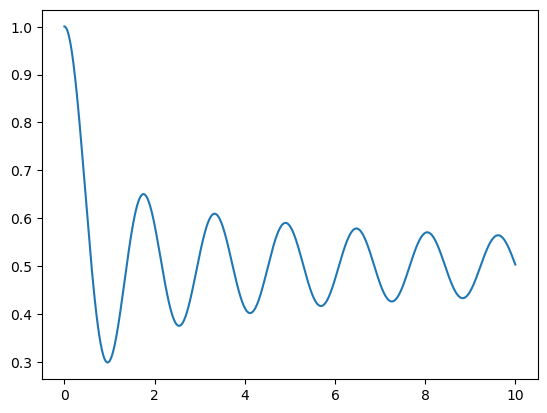

In [42]:
plt.plot(time,n1)

In [34]:
A = dot_eigvec_site0 * dot_site_j_eigvec[1]
B = dot_site_j_eigvec[1].conj() * dot_eigvec_site0.conj()



In [35]:
print(A,B)

[-0.16666667 -0.16666667  0.16666667  0.009756    0.16666667 -0.04939559] [-0.16666667 -0.16666667  0.16666667  0.009756    0.16666667 -0.04939559]


In [38]:
A[:, None] * B[None, :]

array([[ 2.77777778e-02,  2.77777778e-02, -2.77777778e-02,
        -1.62599984e-03, -2.77777778e-02,  8.23259774e-03],
       [ 2.77777778e-02,  2.77777778e-02, -2.77777778e-02,
        -1.62599984e-03, -2.77777778e-02,  8.23259774e-03],
       [-2.77777778e-02, -2.77777778e-02,  2.77777778e-02,
         1.62599984e-03,  2.77777778e-02, -8.23259774e-03],
       [-1.62599984e-03, -1.62599984e-03,  1.62599984e-03,
         9.51795177e-05,  1.62599984e-03, -4.81903295e-04],
       [-2.77777778e-02, -2.77777778e-02,  2.77777778e-02,
         1.62599984e-03,  2.77777778e-02, -8.23259774e-03],
       [ 8.23259774e-03,  8.23259774e-03, -8.23259774e-03,
        -4.81903295e-04, -8.23259774e-03,  2.43992396e-03]])

In [13]:
dot_eigvec_site0

array([ 0.40824829, -0.57735027,  0.40824829, -0.01992069,  0.57735027,
        0.11404433])

In [16]:
dot_site_j_eigvec

array([[ 0.40824829, -0.57735027,  0.40824829, -0.01992069,  0.57735027,
         0.11404433],
       [-0.40824829,  0.28867513,  0.40824829, -0.48974194,  0.28867513,
        -0.4331262 ],
       [ 0.40824829,  0.28867513,  0.40824829,  0.50966263, -0.28867513,
        -0.54717053],
       [-0.40824829, -0.57735027,  0.40824829, -0.01992069, -0.57735027,
        -0.11404433],
       [ 0.40824829,  0.28867513,  0.40824829, -0.48974194, -0.28867513,
         0.4331262 ],
       [-0.40824829,  0.28867513,  0.40824829,  0.50966263,  0.28867513,
         0.54717053]])

In [33]:
A2 = np.array([4,5,6])
A2[:, None] * A2[None, :]

array([[16, 20, 24],
       [20, 25, 30],
       [24, 30, 36]])

In [30]:
A1 = np.array([1,2,3])
exp_term = np.exp(1j * (A1[:, None] - A1[None, :]) * 1)  # (50, 50) matrix
print(exp_term) # print        
print(A1[:, None] - A1[None, :])

[[ 1.        +0.j          0.54030231-0.84147098j -0.41614684-0.90929743j]
 [ 0.54030231+0.84147098j  1.        +0.j          0.54030231-0.84147098j]
 [-0.41614684+0.90929743j  0.54030231+0.84147098j  1.        +0.j        ]]
[[ 0 -1 -2]
 [ 1  0 -1]
 [ 2  1  0]]


In [31]:
np.exp(1j*(-1)*1)

(0.5403023058681398-0.8414709848078965j)

In [12]:
eigvec.T

array([[ 0.40824829, -0.40824829,  0.40824829, -0.40824829,  0.40824829,
        -0.40824829],
       [-0.57735027,  0.28867513,  0.28867513, -0.57735027,  0.28867513,
         0.28867513],
       [ 0.40824829,  0.40824829,  0.40824829,  0.40824829,  0.40824829,
         0.40824829],
       [-0.01992069, -0.48974194,  0.50966263, -0.01992069, -0.48974194,
         0.50966263],
       [ 0.57735027,  0.28867513, -0.28867513, -0.57735027, -0.28867513,
         0.28867513],
       [ 0.11404433, -0.4331262 , -0.54717053, -0.11404433,  0.4331262 ,
         0.54717053]])

In [ ]:
eigenvec, eigenval = np.linalg.eig(6)

In [ ]:
sum1 = np.zeros(6)
site = np.eye(6)
for t in range(6):    
    sum = 0
    for j in range(6):
        for l in range(6):
            for alpha in range(6):
                for beta in range(6):
                    for delta in range(6):
                        for eta in range(6):
                            A = np.dot(eigenvec[:,alpha],site[0])*np.dot(site[0],eigenvec[:,beta])
                            B = np.dot(eigenvec[:,delta],site[0])*np.dot(site[0],eigenvec[:,eta])
                            C = np.dot(eigenvec[:,alpha],site[j])*np.dot(site[l],eigenvec[:,beta])
                            D = np.dot(eigenvec[:,delta],site[l])*np.dot(site[j],eigenvec[:,eta])
                            sum += A*B*C*D*np.exp(1j*(eigenval[alpha]+eigenval[delta]-eigenval[beta]-eigenval[eta]))*(n[j]*n[l]+n[j])
    sum1[t]= sum

In [84]:
eigval,eigvec = np.linalg.eig(H(50))
site = np.eye(50)
neel = np.zeros(50)
neel[::2]=1

In [85]:
import numpy as np
from tqdm import tqdm

# Define time and initialize n1
time = np.linspace(0, 10, 1000)
n1 = np.zeros( len(time), dtype=np.complex128)  # Ensure complex numbers for the result

# Precompute dot products involving 'site' and 'eigvec'
dot_eigvec_site0 = np.dot(eigvec.T, site[:, 0])  # Shape (50,)
dot_site_j_eigvec = np.dot(site.T, eigvec)       # Shape (50, 50)

# Loop over t1

for t in tqdm(range(len(time))):
    sum_result = 0
    
    # Precompute the exponential terms for the current time step
    # Use element-wise multiplication to compute the complex exponential
    for j in range(50):
        A = np.exp(1j*eigval*time[t])*dot_eigvec_site0 * dot_site_j_eigvec[j]  # Vector of length 50 (one for each alpha)
        
        B = np.exp(-1j*eigval*time[t])*dot_site_j_eigvec[j].conj() * dot_eigvec_site0.conj()  # Vector of length 50 (for beta)
        
        # Compute the exponential for each combination of alpha and beta
        # exp_term = np.exp(1j * (eigval[:, None] - eigval[None, :]) * time[t])  # (50, 50) matrix
        # Sum over alpha and beta using vectorized numpy operations
        sum_result += np.sum(A[:, None] * B[None, :]) * neel[j]
        
        
    n1[t] = sum_result


100%|██████████| 1000/1000 [00:01<00:00, 877.28it/s]


c:\Users\aniru\anaconda3\Lib\site-packages\matplotlib\cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\aniru\anaconda3\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


Text(0, 0.5, 'correlation_same_site')

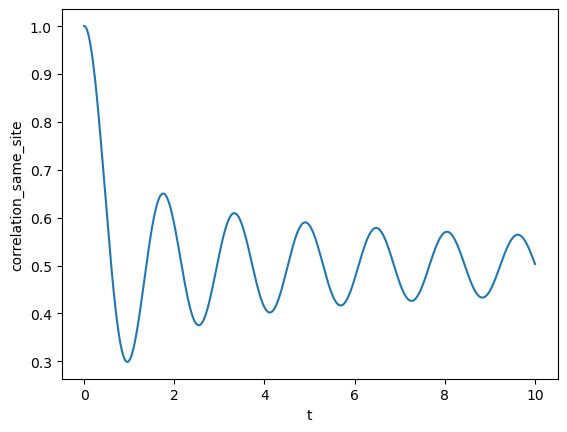

In [87]:
plt.plot(time,n1)
plt.xlabel("t")
plt.ylabel("correlation_same_site")
